## 1. Import Libraries and Load Data

Load the cleaned flight dataset and airline information for analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

analysis = pd.read_csv("data/cleaned/analysis_ready_flights.csv")
airlines = pd.read_csv("data/raw/airlines.csv")

print("Analysis dataset:", analysis.shape)
print("Airline lookup:", airlines.shape)
print("Unique airline codes:", analysis["carrier"].nunique())
print("Missing arrival delays:", analysis["arr_delay"].isna().sum())

Analysis dataset: (327346, 34)
Airline lookup: (16, 2)
Unique airline codes: 16
Missing arrival delays: 0


## 2. Match Airline Names

Merge the flight data with airline names using carrier codes. Check that all airlines are matched correctly.

In [2]:
airline_data = analysis.merge(
    airlines,
    on="carrier",
    how="left",
    validate="many_to_one"
)

print("Rows before merge:", len(analysis))
print("Rows after merge:", len(airline_data))
print("Missing airline names:", airline_data["name"].isna().sum())

display(
    airline_data[["carrier", "name"]]
    .drop_duplicates()
    .sort_values("carrier")
)

Rows before merge: 327346
Rows after merge: 327346
Missing airline names: 0


,carrier,name
116,9E,Endeavor Air Inc.
2,AA,American Airlines Inc.
78,AS,Alaska Airlines Inc.
3,B6,JetBlue Airways
4,DL,Delta Air Lines Inc.
7,EV,ExpressJet Airlines Inc.
145,F9,Frontier Airlines Inc.
74,FL,AirTran Airways Corporation
162,HA,Hawaiian Airlines Inc.
18,MQ,Envoy Air


## 3. Airline Descriptive Statistics

Calculate the number of flights, mean delay, median delay, standard deviation, and percentage of flights delayed more than 15 minutes for each airline.

In [3]:
airline_stats = (
    airline_data.groupby(["carrier", "name"])
    .agg(
        Flights=("arr_delay", "count"),
        Mean_Delay=("arr_delay", "mean"),
        Median_Delay=("arr_delay", "median"),
        Std_Delay=("arr_delay", "std"),
        Delay_Over_15_Pct=(
            "arr_delay",
            lambda x: (x > 15).mean() * 100
        )
    )
    .reset_index()
    .sort_values("Mean_Delay", ascending=False)
)

display(airline_stats.round(2))

,carrier,name,Flights,Mean_Delay,Median_Delay,Std_Delay,Delay_Over_15_Pct
6,F9,Frontier Airlines Inc.,681,21.92,6.0,61.65,37.30
7,FL,AirTran Airways Corporation,3175,20.12,5.0,54.09,33.54
5,EV,ExpressJet Airlines Inc.,51108,15.80,-1.0,49.86,31.36
15,YV,Mesa Airlines Inc.,544,15.56,-2.0,52.92,31.43
10,OO,SkyWest Airlines Inc.,29,11.93,-7.0,48.58,24.14
9,MQ,Envoy Air,25037,10.77,-1.0,43.17,27.07
14,WN,Southwest Airlines Co.,12044,9.65,-3.0,46.88,24.86
3,B6,JetBlue Airways,54049,9.46,-3.0,42.84,26.11
0,9E,Endeavor Air Inc.,17294,7.38,-7.0,50.09,24.92
11,UA,United Air Lines Inc.,57782,3.56,-6.0,40.98,21.79


## 4. Check Airline Sample Sizes

Compare the number of flights across airlines to identify differences in sample sizes that may affect our interpretation.

In [4]:
print("Total flights:", airline_stats["Flights"].sum())

print("\nSmallest airline samples:")
display(
    airline_stats.sort_values("Flights").head(5).round(2)
)

print("\nLargest airline samples:")
display(
    airline_stats.sort_values(
        "Flights", ascending=False
    ).head(5).round(2)
)

Total flights: 327346

Smallest airline samples:


,carrier,name,Flights,Mean_Delay,Median_Delay,Std_Delay,Delay_Over_15_Pct
10,OO,SkyWest Airlines Inc.,29,11.93,-7.0,48.58,24.14
8,HA,Hawaiian Airlines Inc.,342,-6.92,-13.0,75.13,12.57
15,YV,Mesa Airlines Inc.,544,15.56,-2.0,52.92,31.43
6,F9,Frontier Airlines Inc.,681,21.92,6.0,61.65,37.30
2,AS,Alaska Airlines Inc.,709,-9.93,-17.0,36.48,14.39



Largest airline samples:


,carrier,name,Flights,Mean_Delay,Median_Delay,Std_Delay,Delay_Over_15_Pct
11,UA,United Air Lines Inc.,57782,3.56,-6.0,40.98,21.79
3,B6,JetBlue Airways,54049,9.46,-3.0,42.84,26.11
5,EV,ExpressJet Airlines Inc.,51108,15.80,-1.0,49.86,31.36
4,DL,Delta Air Lines Inc.,47658,1.64,-8.0,44.40,18.23
1,AA,American Airlines Inc.,31947,0.36,-9.0,42.52,18.79


## 5. Mean Arrival Delay by Airline

Create a bar chart to compare average arrival delays across airlines.

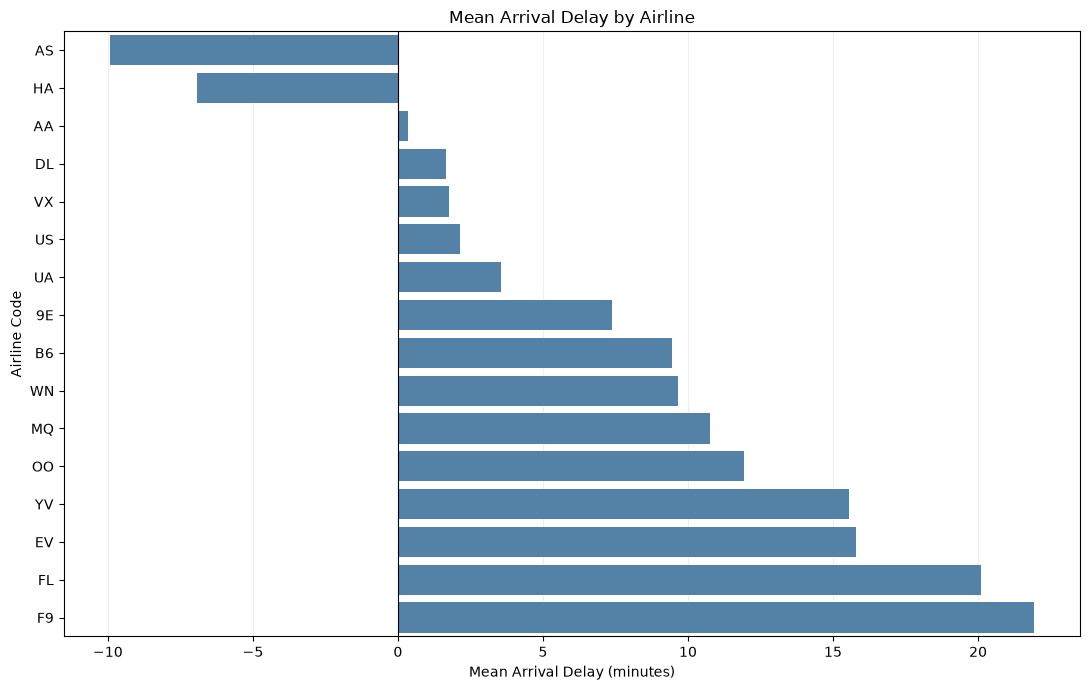

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

fig_dir = Path("results/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

plot_data = airline_stats.sort_values(
    "Mean_Delay", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=plot_data,
    x="Mean_Delay",
    y="carrier",
    color="steelblue",
    ax=ax
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set(
    title="Mean Arrival Delay by Airline",
    xlabel="Mean Arrival Delay (minutes)",
    ylabel="Airline Code"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    fig_dir / "airline_mean_arrival_delay.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 6. Percentage of Flights Delayed More Than 15 Minutes

Visualize the percentage of flights arriving more than 15 minutes late for each airline.

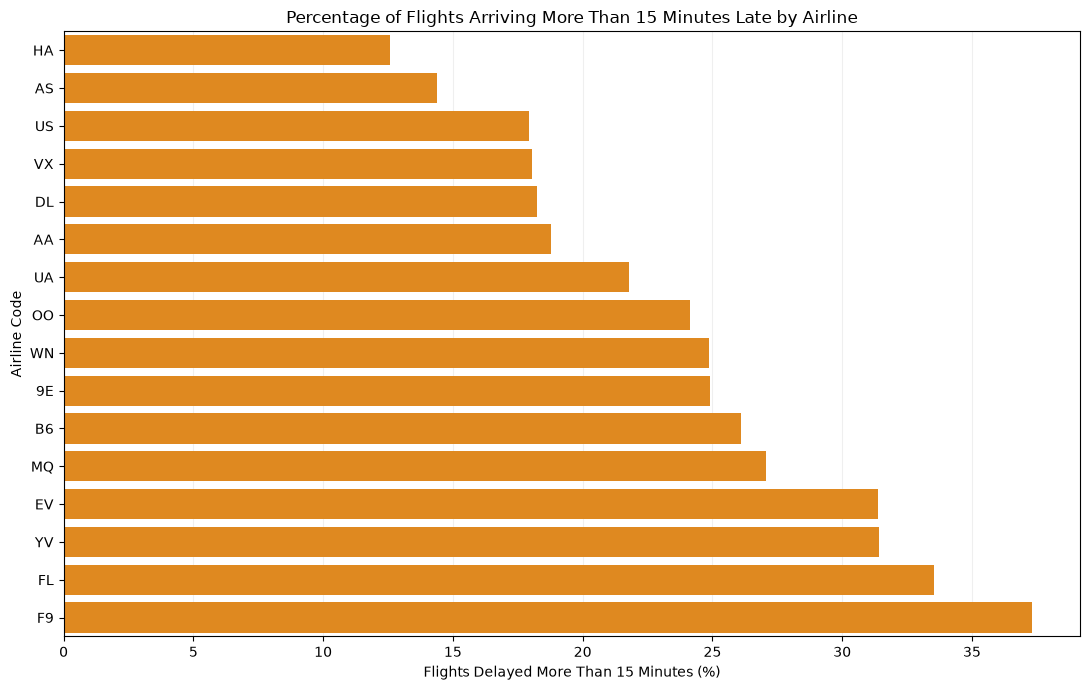

In [6]:
plot_data = airline_stats.sort_values(
    "Delay_Over_15_Pct", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

sns.barplot(
    data=plot_data,
    x="Delay_Over_15_Pct",
    y="carrier",
    color="darkorange",
    ax=ax
)

ax.set(
    title="Percentage of Flights Arriving More Than 15 Minutes Late by Airline",
    xlabel="Flights Delayed More Than 15 Minutes (%)",
    ylabel="Airline Code"
)

ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    fig_dir / "airline_delay_over_15_pct.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [7]:
# Overall average arrival delay
overall_mean = airline_data["arr_delay"].mean()

# Airlines with highest and lowest mean delays
highest = airline_stats.loc[airline_stats["Mean_Delay"].idxmax()]
lowest = airline_stats.loc[airline_stats["Mean_Delay"].idxmin()]

# Airlines with highest and lowest delay rates
highest_rate = airline_stats.loc[
    airline_stats["Delay_Over_15_Pct"].idxmax()
]
lowest_rate = airline_stats.loc[
    airline_stats["Delay_Over_15_Pct"].idxmin()
]

print(f"Overall mean arrival delay: {overall_mean:.2f} minutes")

print(
    f"\nHighest mean delay: {highest['name']} "
    f"({highest['Mean_Delay']:.2f} minutes, "
    f"n={int(highest['Flights']):,})"
)

print(
    f"Lowest mean delay: {lowest['name']} "
    f"({lowest['Mean_Delay']:.2f} minutes, "
    f"n={int(lowest['Flights']):,})"
)

print(
    f"\nHighest delay rate: {highest_rate['name']} "
    f"({highest_rate['Delay_Over_15_Pct']:.2f}%)"
)

print(
    f"Lowest delay rate: {lowest_rate['name']} "
    f"({lowest_rate['Delay_Over_15_Pct']:.2f}%)"
)

Overall mean arrival delay: 6.90 minutes

Highest mean delay: Frontier Airlines Inc. (21.92 minutes, n=681)
Lowest mean delay: Alaska Airlines Inc. (-9.93 minutes, n=709)

Highest delay rate: Frontier Airlines Inc. (37.30%)
Lowest delay rate: Hawaiian Airlines Inc. (12.57%)


### Key Findings

The overall mean arrival delay was 6.90 minutes. Frontier Airlines had the highest mean arrival delay (21.92 minutes), while Alaska Airlines had the lowest (−9.93 minutes), meaning its flights arrived about 10 minutes early on average.

Frontier Airlines also had the highest percentage of flights delayed more than 15 minutes (37.30%), while Hawaiian Airlines had the lowest (12.57%). These results show that average delay and delay rate can provide different information about airline performance.

### Limitations

Some airlines, such as Frontier (681 flights) and Alaska (709 flights), had relatively small sample sizes. Their results should be interpreted carefully.

This analysis only uses flights departing from NYC airports in 2013. It also does not control for other factors, such as season, scheduled departure time, flight distance, or weather conditions. Therefore, these differences do not necessarily mean that the airlines themselves caused the delays.